## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [ ]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Heidi Williams

**Date:** 10/21/2026

In [1]:
from google.colab import drive
drive.mount('/content/drive')

%cd /content/drive/MyDrive/ML/A05-pca
!ls

Mounted at /content/drive
/content/drive/MyDrive/ML/A05-pca
data  notebook.ipynb  README.md


In [3]:
#Q1
#code to run
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

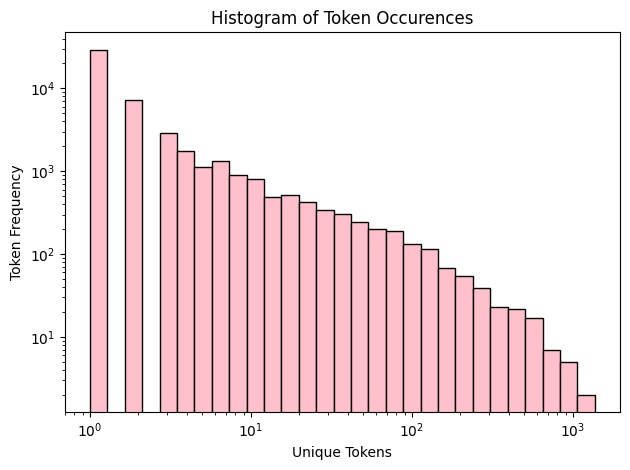

In [4]:
import matplotlib.pyplot as plt
import numpy as np

counts = list(token_count.values())
bins = np.logspace(0, np.log10(max(counts) + 1), 30)

plt.hist(counts, bins=bins, color="pink", edgecolor="black")

plt.xscale("log")
plt.yscale("log")
#used for scaling
plt.xlabel("Unique Tokens")
plt.ylabel("Token Frequency")
plt.title("Histogram of Token Occurences")
plt.tight_layout()
plt.show()

The histogram is skewed right, which means that most of the tokens have a lower frequency on the log scale (many only one and most under 100). The few that are over 100 occurances further add to the right skew by creating a tail.

In [5]:
#Q2
#1
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_parquet("data/Phishing_clean.parquet")
X = df.drop(columns="Email Type")
y = df["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
#Q2
#2
from sklearn.linear_model import LinearRegression
model = LinearRegression().fit(X_train, y_train)

print(model.score(X_test, y_test))
print(model.score(X_train, y_train))

0.6658718438847919
0.7670143724934355


The test R squared was 0.6658718438847919 and the training R squared was  0.7670143724934355.

In [7]:
#Q2
#3
coefficients = pd.Series(model.coef_, index=X.columns)
print(coefficients.sort_values(key=abs, ascending=False).head(20))

intervention        -1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:   -0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;               -0.574480
a:active             0.574480
retrieving          -0.573761
zdnet               -0.560954
{text-decoration:    0.497075
xanaax               0.491981
transcript           0.488978
shopper             -0.486678
april's             -0.486483
arial,              -0.482141
laser                0.473607
issue:              -0.465547
dtype: float64


Intervention had the largest coefficient by absolute value; it very strongly pushes towards a legitamate email. Localized had the largest positive value, pushing an email greatly towards being a phishing email.

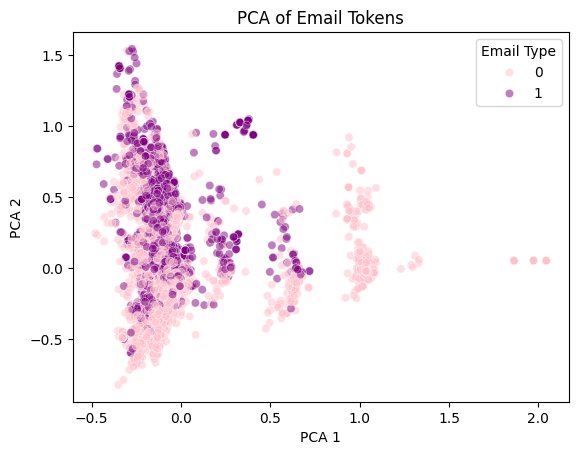

In [8]:
#Q3
from sklearn.decomposition import PCA
import seaborn as sns

components = PCA(n_components=2).fit_transform(X)

sns.scatterplot(x=components[:, 0], y=components[:, 1], hue=y, palette={0: "pink", 1: "purple"}, alpha=0.5)

plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("PCA of Email Tokens")
plt.show()

This plot shows a lot of overlap between -0.5 and 0.5 on PCA 1, so there is not a clear separation between phishing and legitimate emails in that specific range. The points almost look like they form vertical bands, which could mean some emails use similar words. Farther to the right, especially around 1, the emails are mostly legitimate, but there are still phishing emails near 0.5

In [9]:
#Q4
pca = PCA(n_components=2610)
train_pca = pca.fit_transform(X_train)
test_pca = pca.transform(X_test)

pca_model = LinearRegression().fit(train_pca, y_train)

print(pca_model.score(train_pca, y_train))
print( pca_model.score(test_pca, y_test))

0.7662326827745849
0.6683390643101164


The PCA training R squared is 0.7662326827745849 and the PCA test R squared is 0.6683390643101164.

This performance is similar to the linear regression, as they only begin to differ in the thousandths place. The PCA training R squared was slightly lower by about 0.0008 while the test R squared was slightly higher by about 0.0024.This concludes that PCA did perform better, but by a slim margin.

Q5

The advantage of using PCA is that it combines information from the tokens into fewer variables that are not correlated with each other. In our results,we decreased the number by 101 variables in the PCA analysis and still had very similar R squared values. The test performance was even slightly higher, showing that we could remove some information without hurting predictions; the clear advantage of PCA.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]